In [9]:
import numpy as np
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
import pandas as pd
import requests

DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
print(f'Używane urządzenie: {DEVICE}')

Używane urządzenie: cuda


In [10]:
url = "https://archive-api.open-meteo.com/v1/archive?latitude=52.2298&longitude=21.0118&start_date=2020-01-01&end_date=2023-12-31&daily=temperature_2m_mean&timezone=Europe%2FWarsaw"
response = requests.get(url).json()

seria = np.array(response['daily']['temperature_2m_mean'], dtype=np.float32)
seria = seria[~np.isnan(seria)]

n = len(seria)
i_tr = int(0.7 * n)
i_va = int(0.85 * n)

mu, sd = seria[:i_tr].mean(), seria[:i_tr].std()
s = (seria - mu) / sd

In [11]:
def zrob_okna(szereg, okno, i_lo, i_hi):
    X, Y = [], []
    for i in range(max(okno, i_lo), i_hi):
        X.append(szereg[i-okno:i])
        Y.append(szereg[i])
    return np.array(X, np.float32)[..., None], np.array(Y, np.float32)[:, None]

class ModelGRU(nn.Module):
    def __init__(self, hidden=32):
        super().__init__()
        self.rnn = nn.GRU(1, hidden, batch_first=True)
        self.fc = nn.Linear(hidden, 1)
    def forward(self, x):
        out, _ = self.rnn(x)
        return self.fc(out[:, -1, :])

def trenuj(model, Xtr, Ytr, Xva, Yva, epoki=40, lr=1e-2, batch=64):
    model = model.to(DEVICE)
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    L = nn.MSELoss()
    best = 1e9
    best_state = None
    hist_tr, hist_va = [], []
    best_ep = 0

    for ep in range(epoki):
        model.train()
        perm = torch.randperm(len(Xtr))
        tr_loss = 0
        for i in range(0, len(Xtr), batch):
            idx = perm[i:i+batch]
            opt.zero_grad()
            loss = L(model(Xtr[idx]), Ytr[idx])
            loss.backward()
            opt.step()
            tr_loss += loss.item() * len(idx)
        hist_tr.append(tr_loss / len(Xtr))

        model.eval()
        with torch.no_grad():
            v = L(model(Xva), Yva).item()
        hist_va.append(v)
        if v < best:
            best = v
            best_ep = ep
            best_state = {k: val.clone() for k, val in model.state_dict().items()}

    model.load_state_dict(best_state)
    return model, hist_tr, hist_va, best, best_ep

def mae(a, b): return float(np.mean(np.abs(a - b)))
def rmse(a, b): return float(np.sqrt(np.mean((a - b)**2)))

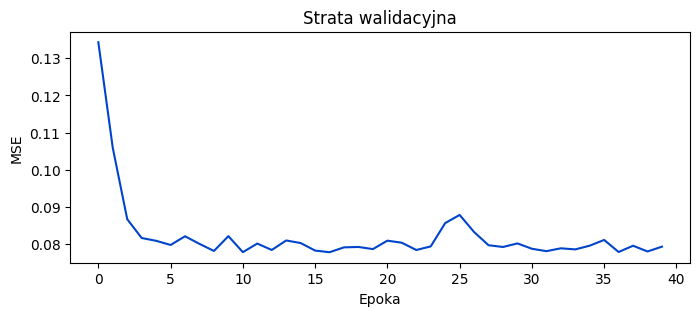

In [12]:
torch.manual_seed(0)
np.random.seed(0)
OKNO_BAZA = 28
to_t = lambda a: torch.tensor(a).to(DEVICE)

Xtr, Ytr = zrob_okna(s, OKNO_BAZA, OKNO_BAZA, i_tr)
Xva, Yva = zrob_okna(s, OKNO_BAZA, i_tr, i_va)
Xte, Yte = zrob_okna(s, OKNO_BAZA, i_va, n)
Xtr, Ytr, Xva, Yva, Xte, Yte = map(to_t, [Xtr, Ytr, Xva, Yva, Xte, Yte])

model_baza, hist_tr, hist_va, best_val, best_ep = trenuj(ModelGRU(32), Xtr, Ytr, Xva, Yva)

plt.figure(figsize=(8,3))
plt.plot(hist_va, color='#0044cc')
plt.title('Strata walidacyjna')
plt.xlabel('Epoka')
plt.ylabel('MSE')
plt.show()

        Metoda  MAE (1 krok)  RMSE (1 krok)  MAE (Wielokrok H=14)  RMSE (Wielokrok H=14)
           GRU      1.665650       2.182033              2.870775               3.751971
  Naiwny (t-1)      1.793636       2.309289              3.466667               4.276069
Sezonowy (t-7)      3.335455       4.157599              3.595238               4.448445


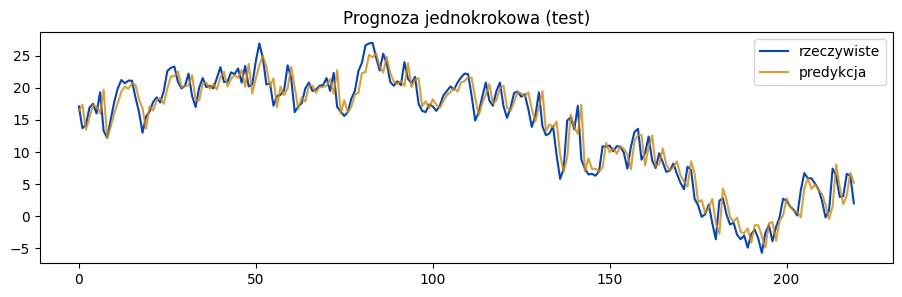

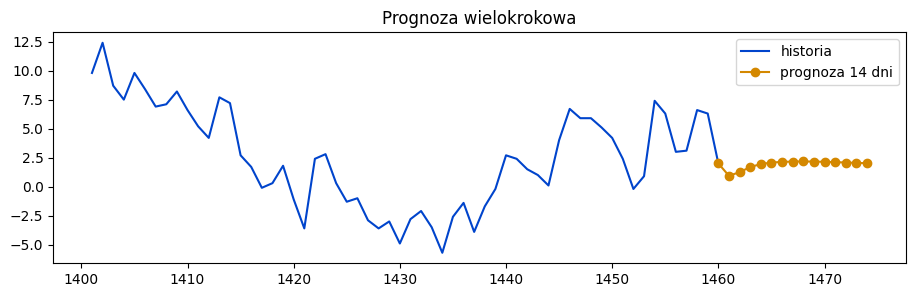

In [18]:
H = 14
start_indices = list(range(i_va, n - H + 1, H))

prawdziwe_h = []
gru_h = []
naiwne_h = []
sezonowe_h = []

model_baza.eval()
for t0 in start_indices:
    prawdziwe = seria[t0:t0+H]

    naiwne = np.full(H, seria[t0-1])
    sezonowe = np.array([seria[t0 - 7 + (i % 7)] for i in range(H)])

    okno = s[t0-OKNO_BAZA : t0].tolist()
    preds = []
    for _ in range(H):
        x = torch.tensor(np.array(okno[-OKNO_BAZA:], np.float32).reshape(1, OKNO_BAZA, 1)).to(DEVICE)
        with torch.no_grad():
            nx = model_baza(x).item()
        preds.append(nx)
        okno.append(nx)
    gru_preds = np.array(preds) * sd + mu

    prawdziwe_h.append(prawdziwe)
    gru_h.append(gru_preds)
    naiwne_h.append(naiwne)
    sezonowe_h.append(sezonowe)

prawdziwe_h = np.array(prawdziwe_h)
gru_h = np.array(gru_h)
naiwne_h = np.array(naiwne_h)
sezonowe_h = np.array(sezonowe_h)

with torch.no_grad():
    pred_1krok = model_baza(Xte).cpu().numpy().ravel()
gru_1krok = pred_1krok * sd + mu
true_1krok = Yte.cpu().numpy().ravel() * sd + mu
tgt = np.arange(i_va, n)
naive_1krok = seria[tgt-1]
seasonal_1krok = seria[tgt-7]

tabela_z2 = pd.DataFrame({
    "Metoda": ["GRU", "Naiwny (t-1)", "Sezonowy (t-7)"],
    "MAE (1 krok)": [mae(true_1krok, gru_1krok), mae(true_1krok, naive_1krok), mae(true_1krok, seasonal_1krok)],
    "RMSE (1 krok)": [rmse(true_1krok, gru_1krok), rmse(true_1krok, naive_1krok), rmse(true_1krok, seasonal_1krok)],
    "MAE (Wielokrok H=14)": [mae(prawdziwe_h, gru_h), mae(prawdziwe_h, naiwne_h), mae(prawdziwe_h, sezonowe_h)],
    "RMSE (Wielokrok H=14)": [rmse(prawdziwe_h, gru_h), rmse(prawdziwe_h, naiwne_h), rmse(prawdziwe_h, sezonowe_h)]
})
print(tabela_z2.to_string(index=False))

plt.figure(figsize=(11,3))
plt.plot(true_1krok, label='rzeczywiste', color='#0044cc')
plt.plot(gru_1krok, label='predykcja', color='#d48800', alpha=0.8)
plt.legend()
plt.title('Prognoza jednokrokowa (test)')
plt.show()

okno_2 = s[n-OKNO_BAZA:].tolist()
preds_2 = []
model_baza.eval()
for _ in range(H):
    x = torch.tensor(np.array(okno_2[-OKNO_BAZA:],np.float32).reshape(1,OKNO_BAZA,1)).to(DEVICE)
    with torch.no_grad(): nx = model_baza(x).item()
    preds_2.append(nx); okno_2.append(nx)
preds_raw_2 = np.array(preds_2)*sd + mu

plt.figure(figsize=(11,3))
plt.plot(range(n-60, n), seria[n-60:], label='historia', color='#0044cc')

x_pred = [n-1] + list(range(n, n+H))
y_pred = [seria[-1]] + preds_raw_2.tolist()

plt.plot(x_pred, y_pred, 'o-', label=f'prognoza {H} dni', color='#d48800')
plt.legend()
plt.title('Prognoza wielokrokowa')
plt.show()

In [14]:
wyniki = []

for okno_len in [3, 7, 28]:
    for seed in [0, 1]:
        torch.manual_seed(seed)
        np.random.seed(seed)

        Xtr, Ytr = zrob_okna(s, okno_len, okno_len, i_tr)
        Xva, Yva = zrob_okna(s, okno_len, i_tr, i_va)
        Xte, Yte = zrob_okna(s, okno_len, i_va, n)
        Xtr, Ytr, Xva, Yva, Xte, Yte = map(to_t, [Xtr, Ytr, Xva, Yva, Xte, Yte])

        model_eks, _, _, val_loss, _ = trenuj(ModelGRU(32), Xtr, Ytr, Xva, Yva)

        model_eks.eval()
        with torch.no_grad():
            pred_1krok = model_eks(Xte).cpu().numpy().ravel()
        gru_1krok = pred_1krok * sd + mu
        true_1krok = Yte.cpu().numpy().ravel() * sd + mu
        mae_1krok = mae(true_1krok, gru_1krok)

        gru_h_eks = []
        prawdziwe_h_eks = []
        for t0 in start_indices:
            prawdziwe = seria[t0:t0+H]
            okn = s[t0-okno_len : t0].tolist()
            preds = []
            for _ in range(H):
                x = torch.tensor(np.array(okn[-okno_len:], np.float32).reshape(1, okno_len, 1)).to(DEVICE)
                with torch.no_grad(): nx = model_eks(x).item()
                preds.append(nx)
                okn.append(nx)
            gru_h_eks.append(np.array(preds) * sd + mu)
            prawdziwe_h_eks.append(prawdziwe)

        mae_wielokrok = mae(np.array(prawdziwe_h_eks), np.array(gru_h_eks))

        wyniki.append({
            "Okno": okno_len,
            "Ziarno": seed,
            "Strata Val (MSE)": val_loss,
            "MAE 1-krok": mae_1krok,
            "MAE Wielokrok": mae_wielokrok
        })

tabela_z3 = pd.DataFrame(wyniki)
print(tabela_z3.to_string(index=False))

 Okno  Ziarno  Strata Val (MSE)  MAE 1-krok  MAE Wielokrok
    3       0          0.078963    1.754496       3.187162
    3       1          0.079269    1.821737       3.782196
    7       0          0.077725    1.689964       2.740006
    7       1          0.076965    1.715685       2.811952
   28       0          0.077766    1.665650       2.870775
   28       1          0.077814    1.686261       2.960075
